In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [2]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 100
subband energies= 0.6631720133634798 1.9895160400904393
4t= 265.2688053453919
mu =  0.7958064160361757


In [3]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
XCT = np.linspace((NSC-200)*AX, (NSC+NSM+200)*AX, 51)
YCT = M/2*AY
ZCT = 50
ZIM = 64

print('y charge trap =', YCT)

Ep = np.empty((XCT.shape[0],K_NUM))

for i in range(XCT.shape[0]):

    H = ModCT.H_sys(PHI, 'li', XCT[i], YCT, ZCT, ZIM)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    if i%5==0:
        print(Ep[i,:])

np.save('linear_E_vs_xct_Zdiff_{}_greater_length_beyond_sm.npy'.format(ZIM-ZCT), Ep)

y charge trap = 150.0
[-0.89260119 -0.88934597 -0.35798293 -0.3560072   0.3560072   0.35798293
  0.88934597  0.89260119]
[-0.89251843 -0.88926376 -0.3579787  -0.35600335  0.35600335  0.3579787
  0.88926376  0.89251843]
[-0.89228232 -0.88902923 -0.3579735  -0.35599922  0.35599922  0.3579735
  0.88902923  0.89228232]
[-0.89126808 -0.88802196 -0.35802988 -0.35606047  0.35606047  0.35802988
  0.88802196  0.89126808]
[-0.87942524 -0.87630467 -0.36359221 -0.36171103  0.36171103  0.36359221
  0.87630467  0.87942524]
[-0.76823626 -0.76737605 -0.36155561 -0.36089909  0.36089909  0.36155561
  0.76737605  0.76823626]
[-0.87851371 -0.87540886 -0.36436045 -0.36248982  0.36248982  0.36436045
  0.87540886  0.87851371]
[-0.89121852 -0.88797275 -0.35803527 -0.3560661   0.3560661   0.35803527
  0.88797275  0.89121852]
[-0.89227322 -0.88902018 -0.35797347 -0.35599923  0.35599923  0.35797347
  0.88902018  0.89227322]
[-0.89251562 -0.88926097 -0.35797859 -0.35600324  0.35600324  0.35797859
  0.88926097  0.

In [25]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\linear_E_vs_xct_Zdiff_0.20000000000000284.npy")


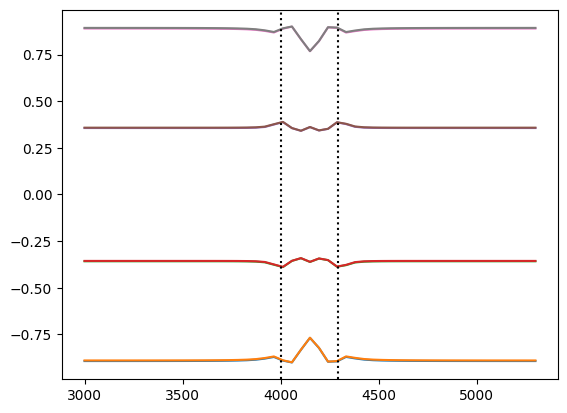

In [4]:
plt.plot(XCT, Ep[:, :])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

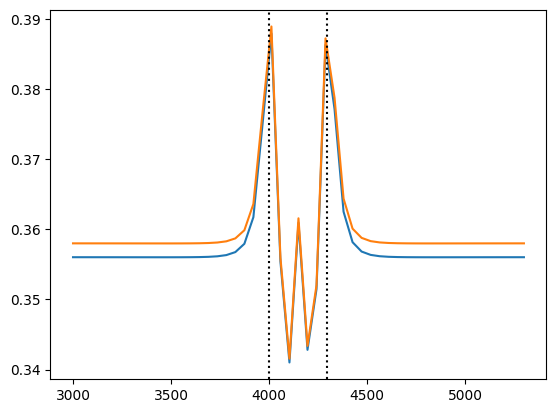

In [5]:
plt.plot(XCT, Ep[:, K_NUM//2:K_NUM//2+2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

(0.0, 0.0023708722225180166)

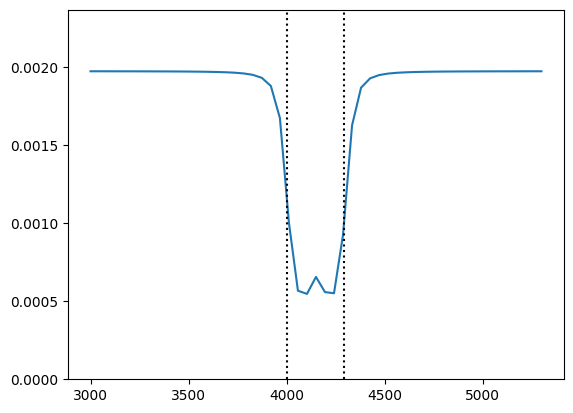

In [6]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.ylim(ymin=0)
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

(0.0, 0.0023708722225180166)

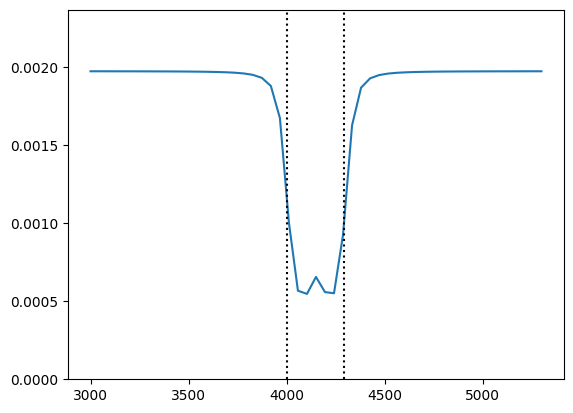

In [7]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.ylim(ymin=0)
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

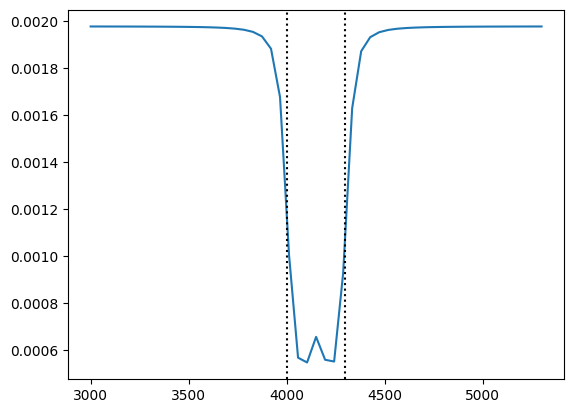

In [8]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

In [9]:
linear_spin_split = Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2] 

min_spin_split = np.min(linear_spin_split)

max_spin_split = np.max(linear_spin_split)

percent_spin_split = (max_spin_split-min_spin_split)/max_spin_split

print(percent_spin_split)

0.7059000927567326


In [13]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\linear_E_vs_xct_V1.npy")

(0.0, 0.0023691305210776113)

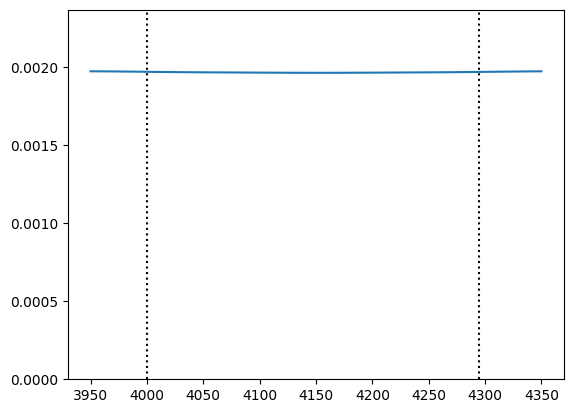

In [14]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))